# CESM2-LE CAM6 forcing for a regional MOM6 DATM case

Edit **User settings** once, then run cells in order. The source is one CESM2-LE scenario/member on its native regular CAM latitude–longitude grid. The ESMF source mesh describes that grid; **CDEPS does the bilinear CAM → regional grid remapping at run time**. The optional plotted regional interpolation is only a check and is never written as forcing.

**Data inspection is the default.** To register eight DATM streams and build a technical run, first inspect the plots, daily radiation timing, and lowest CAM model-level height; then set `PLUMBING_TEST=True` in User settings and rerun. This test uses daily radiation held constant over each day and bottom model-level T/q/wind in bulk-flux slots. It is unsuitable for interpreting Milton's hourly air–sea fluxes. A free-running CESM2-LE member dated October 2024 is not a hindcast of observed Hurricane Milton.

Cells labeled **Terminal (CLI)** are shell commands to run manually.

In [13]:
from datetime import datetime, timedelta
from pathlib import Path
from xml.etree import ElementTree as ET
from xml.sax.saxutils import escape
import re
import shutil

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from netCDF4 import Dataset
from scipy.interpolate import RegularGridInterpolator

# ============================ USER SETTINGS ============================
ARCHIVE = Path('/gdex/data/d651056/CESM2-LE/atm/proc/tseries')
SCENARIO = 'BSSP370smbb'
MEMBER = 'LE2-1011.001'
MODE_NAME = 'CESM2LE_CAM6'      # Unique CIME DATM_MODE; new name for a new forcing period
CASE_NAME = 'florida_storm_cam6_test'
INPUT_NAME = CASE_NAME
CESM_ROOT = Path('/glade/work/hmnguyen/crocodile2026/CESM')
CASE_ROOT = Path('/glade/u/home/hmnguyen/work/crocodile2026/croc_cases')
FORCING_ROOT = Path('/glade/work/hmnguyen/cam6_forcing')

RUN_START = datetime(2024, 10, 1, 0)
RUN_END = datetime(2024, 11, 1, 0)      # Exclusive
FORCING_START = datetime(2024, 10, 1, 0)
FORCING_END = datetime(2024, 11, 2, 0)  # Last 6-hour input record
GLORYS_PAD_DAYS = 2
HIST_OPTION, HIST_N = 'ndays', 1           # Mediator history only

WEST, EAST, SOUTH, NORTH = 267., 286., 20., 33.
HALO_CELLS = 2
MODEL_WEST, MODEL_EAST = 267., 285.
MODEL_SOUTH, MODEL_NORTH = 25., 32.
MODEL_RESOLUTION = 1 / 16
SNAPSHOT = datetime(2024, 10, 1, 0)

PLOT_HOURLY_PRECT = True
PLUMBING_TEST = True  # True explicitly enables bottom-level and daily-radiation proxies
SAVE_PLOTS = False

# Map source variable names/frequencies. Edit these if using another CAM archive.
SIX_HOURLY = {
    'U':    ('UBOT', 'hour_6', False),
    'V':    ('VBOT', 'hour_6', False),
    'TBOT': ('T', 'hour_6', True),
    'SHUM': ('Q', 'hour_6', True),
    'PSLV': ('PSL', 'hour_6', False),
    'PS':   ('PS', 'hour_6', False),
    'Z3':   ('Z3', 'hour_6', True),
    'PREC': ('PRECT', 'hour_6', False),
}
RADIATION = {'SWDN': ('FSDS', 'day_1'), 'LWDN': ('FLDS', 'day_1')}
HOURLY_PRECIP = ('PRECT', 'hour_1')
OUTPUT_NAMES = {
    'U':'CAM_UBOT', 'V':'CAM_VBOT', 'TBOT':'CAM_T_BOTTOM',
    'SHUM':'CAM_Q_BOTTOM', 'PSLV':'CAM_PSL', 'PS':'CAM_PS',
    'Z3':'CAM_Z3_BOTTOM', 'PREC':'CAM_PRECT',
    'SWDN':'CAM_SWDN', 'LWDN':'CAM_LWDN',
}
# ========================== END USER SETTINGS ==========================

assert ARCHIVE.is_dir(), ARCHIVE
assert re.fullmatch(r'[A-Za-z][A-Za-z0-9_]*', MODE_NAME)
assert 0 <= WEST < EAST <= 360 and SOUTH < NORTH
assert FORCING_START <= RUN_START < RUN_END < FORCING_END
assert FORCING_START <= SNAPSHOT <= FORCING_END
assert all(d.minute == d.second == d.microsecond == 0
           for d in (RUN_START, RUN_END, FORCING_START, FORCING_END))
assert GLORYS_PAD_DAYS >= 0
RUN_HOURS = (RUN_END-RUN_START).total_seconds()/3600
assert RUN_HOURS.is_integer()
RUN_HOURS = int(RUN_HOURS)
STOP_OPTION = 'ndays' if RUN_HOURS % 24 == 0 else 'nhours'
STOP_N = RUN_HOURS // (24 if STOP_OPTION == 'ndays' else 1)
GLORYS_DATE_RANGE = [f'{RUN_START:%Y-%m-%d %H:%M:%S}',
                     f'{RUN_END+timedelta(days=GLORYS_PAD_DAYS):%Y-%m-%d %H:%M:%S}']
CASE = CASE_ROOT / CASE_NAME
OUT = FORCING_ROOT / CASE_NAME
OUT.mkdir(parents=True, exist_ok=True)
FORCING_FILE = OUT / f'{MODE_NAME}_{FORCING_START:%Y%m%d%H}_{FORCING_END:%Y%m%d%H}_DATM.nc'
CORE_FILE = OUT / f'{MODE_NAME}_{FORCING_START:%Y%m%d%H}_{FORCING_END:%Y%m%d%H}_candidates.nc'
SOURCE_MESH = OUT / f'{MODE_NAME}_ESMFmesh.nc'
ATM_MESH = OUT / 'Regional_ATM_ESMFmesh.nc'
CONFIG_DIR = CESM_ROOT / 'components/cdeps/datm/cime_config'
print('Member:', SCENARIO, MEMBER, '| case:', CASE)
print('Run:', RUN_START, RUN_END, '|', STOP_OPTION, STOP_N)
print('Forcing:', FORCING_START, FORCING_END)
print('GLORYS:', GLORYS_DATE_RANGE)
print('CAM source mesh:', SOURCE_MESH)
print('Plumbing test enabled:', PLUMBING_TEST)
print("ATM_DOMAIN_MESH:", ATM_MESH)

Member: BSSP370smbb LE2-1011.001 | case: /glade/u/home/hmnguyen/work/crocodile2026/croc_cases/florida_storm_cam6_test
Run: 2024-10-01 00:00:00 2024-11-01 00:00:00 | ndays 31
Forcing: 2024-10-01 00:00:00 2024-11-02 00:00:00
GLORYS: ['2024-10-01 00:00:00', '2024-11-03 00:00:00']
CAM source mesh: /glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/CESM2LE_CAM6_ESMFmesh.nc
Plumbing test enabled: True


## 1. Locate the CAM files

Each variable is a separate multi-year file. Match both the scenario and member, then select the file whose named span overlaps the forcing window. Only the cropped data will be loaded.

In [14]:
def span(path):
    m = re.search(
        r'\.(\d{8}(?:\d{2})?)-(\d{8}(?:\d{2})?)\.nc$',
        path.name,
    )
    if not m:
        raise ValueError(f'Cannot parse file date span: {path}')

    first, last = m.groups()
    return (
        first + '00' if len(first) == 8 else first,
        last + '23' if len(last) == 8 else last,
    )

def find_files(source, frequency, *, required=True):
    folder = ARCHIVE / frequency / source
    pattern = f'*{SCENARIO}*.{MEMBER}.cam.*.{source}.*.nc'
    matches = sorted(folder.glob(pattern))
    lo, hi = f'{FORCING_START:%Y%m%d%H}', f'{FORCING_END:%Y%m%d%H}'
    selected = [p for p in matches if span(p)[0] <= hi and span(p)[1] >= lo]
    if required and not selected:
        raise FileNotFoundError(f'No {frequency}/{source} for {SCENARIO}/{MEMBER}: {folder}')
    return selected

six_paths = {slot: find_files(source, freq)
             for slot, (source, freq, bottom) in SIX_HOURLY.items()}
rad_paths = {slot: find_files(source, freq, required=False)
             for slot, (source, freq) in RADIATION.items()}
hourly_paths = find_files(*HOURLY_PRECIP, required=False) if PLOT_HOURLY_PRECT else []
for label, group in (('six-hourly', six_paths), ('daily radiation', rad_paths)):
    print(label)
    for slot, paths in group.items():
        print(f'  {slot:5s}', [p.name for p in paths])
print('hourly PRECT:', [p.name for p in hourly_paths])
for slot in ('U', 'TBOT', 'PREC'):
    source = SIX_HOURLY[slot][0]
    with xr.open_dataset(six_paths[slot][0]) as header:
        print(slot, 'calendar:', header.time.encoding.get('calendar'),
              'levels:', header[source].sizes.get('lev', '-'),
              'units:', header[source].attrs.get('units'),
              'cell_methods:', header[source].attrs.get('cell_methods', '-'))

six-hourly
  U     ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.UBOT.2015010100-2024123100.nc']
  V     ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.VBOT.2015010100-2024123100.nc']
  TBOT  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h5.T.2015010100-2024123100.nc']
  SHUM  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h5.Q.2015010100-2024123100.nc']
  PSLV  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.PSL.2015010100-2024123100.nc']
  PS    ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.PS.2015010100-2024123100.nc']
  Z3    ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h5.Z3.2015010100-2024123100.nc']
  PREC  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.PRECT.2015010100-2024123100.nc']
daily radiation
  SWDN  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h1.FSDS.20150101-20241231.nc']
  LWDN  ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h1.FLDS.20150101-20241231.nc']
hourly PRECT: ['b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h4.PRECT.2015010100-2025010100.nc']
U calendar: nole

## 2. Crop on the native CAM grid

CAM provides one-dimensional `lat` and `lon`. Select the time, latitudes, longitudes, and lowest model level **before** calling `.load()`. The halo leaves interpolation neighbors around the requested rectangle. No global field is materialized.

In [15]:
def crop(paths, source, *, bottom=False):
    parts = []
    for path in paths:
        with xr.open_dataset(path) as ds:
            if source not in ds:
                raise KeyError((path, source))
            # The selected Florida longitudes do not cross the 0/360 seam.
            lon = (ds.lon.values % 360.)
            assert np.all(np.diff(lon) > 0), 'Inspect longitude order/seam'
            dlon = np.median(np.diff(lon))
            dlat = np.median(np.diff(ds.lat.values))
            assert dlon > 0 and dlat > 0
            a = ds[source].sel(time=slice(
                f'{FORCING_START:%Y-%m-%d %H:%M:%S}',
                f'{FORCING_END:%Y-%m-%d %H:%M:%S}'))
            if bottom:
                assert 'lev' in a.dims
                a = a.isel(lev=-1, drop=True)
            a = a.sel(lon=slice(WEST-HALO_CELLS*dlon, EAST+HALO_CELLS*dlon),
                      lat=slice(SOUTH-HALO_CELLS*dlat, NORTH+HALO_CELLS*dlat))
            if not all(a.sizes.get(k, 0) for k in ('time', 'lat', 'lon')):
                raise ValueError(('Empty CAM subset', path))
            parts.append(a.transpose('time', 'lat', 'lon').load())
    a = xr.concat(parts, dim='time') if len(parts) > 1 else parts[0]
    a = a.sortby('time')
    assert len(np.unique(a.time.values)) == a.sizes['time'], source
    return a

cam = {}
for slot, (source, freq, bottom) in SIX_HOURLY.items():
    print('Loading cropped', slot, source)
    cam[slot] = crop(six_paths[slot], source, bottom=bottom)

ref = cam['U']
for slot, a in cam.items():
    for dim in ('time', 'lat', 'lon'):
        np.testing.assert_array_equal(a[dim].values, ref[dim].values,
                                      err_msg=f'{slot} differs in {dim}')
    assert np.isfinite(a.values).all(), slot
    print(f'{slot:5s} {a.attrs.get("units", "?"):7s} '
          f'[{np.min(a.values):.3g}, {np.max(a.values):.3g}]')
assert cam['PREC'].attrs.get('units') == 'm/s'
assert cam['TBOT'].attrs.get('units') == 'K'
assert cam['SHUM'].attrs.get('units') in ('kg/kg', 'kg kg-1')
assert cam['PSLV'].attrs.get('units') == 'Pa'

def as_datetime(value):
    # cftime.DatetimeNoLeap -> Python datetime for the October 2024 window.
    return datetime(value.year, value.month, value.day,
                    value.hour, value.minute, value.second)

dates = [as_datetime(t) for t in ref.time.values]
assert dates[0] <= FORCING_START and dates[-1] >= FORCING_END
assert all(b-a == timedelta(hours=6) for a, b in zip(dates, dates[1:])), (
    'Expected six-hour spacing after conversion to Gregorian; noleap windows '
    'crossing leap day require a noleap case/calendar plan')
assert dates[-1] > RUN_END
print('Subset:', ref.shape, dates[0], dates[-1])
print('Lowest CAM lev coordinate:', ref.lev.values[-1] if 'lev' in ref.coords else
      'check original T file', 'Z3 range (m above sea level):',
      float(cam['Z3'].min()), float(cam['Z3'].max()))

daily = {}
for slot, paths in rad_paths.items():
    if paths:
        a = crop(paths, RADIATION[slot][0])
        np.testing.assert_array_equal(a.lat, ref.lat)
        np.testing.assert_array_equal(a.lon, ref.lon)
        daily[slot] = a
        print('Daily', slot, a.attrs.get('units'), a.attrs.get('cell_methods'),
              as_datetime(a.time.values[0]), as_datetime(a.time.values[-1]))
hourly = crop(hourly_paths, HOURLY_PRECIP[0]) if hourly_paths else None

Loading cropped U UBOT
Loading cropped V VBOT
Loading cropped TBOT T
Loading cropped SHUM Q
Loading cropped PSLV PSL
Loading cropped PS PS
Loading cropped Z3 Z3
Loading cropped PREC PRECT
U     m/s     [-17.7, 13.3]
V     m/s     [-15.6, 18.5]
TBOT  K       [277, 309]
SHUM  kg/kg   [0.00267, 0.0224]
PSLV  Pa      [9.97e+04, 1.03e+05]
PS    Pa      [9.56e+04, 1.03e+05]
Z3    m       [63.3, 445]
PREC  m/s     [0, 1.33e-06]
Subset: (129, 18, 19) 2024-10-01 00:00:00 2024-11-02 00:00:00
Lowest CAM lev coordinate: check original T file Z3 range (m above sea level): 63.272281646728516 445.13751220703125
Daily SWDN W/m2 time: mean 2024-10-01 00:00:00 2024-11-02 00:00:00
Daily LWDN W/m2 time: mean 2024-10-01 00:00:00 2024-11-02 00:00:00


## 3. Inspect the fields and time treatment

The wind, temperature, humidity, and height are from CAM's bottom *model level*, not 10 m or 2 m diagnostics. `PRECT` is a mean rate in m/s; multiply by `3,600,000` to plot mm/hour. Daily `FSDS/FLDS` are printed separately and must not be interpreted as instantaneous six-hour radiation.

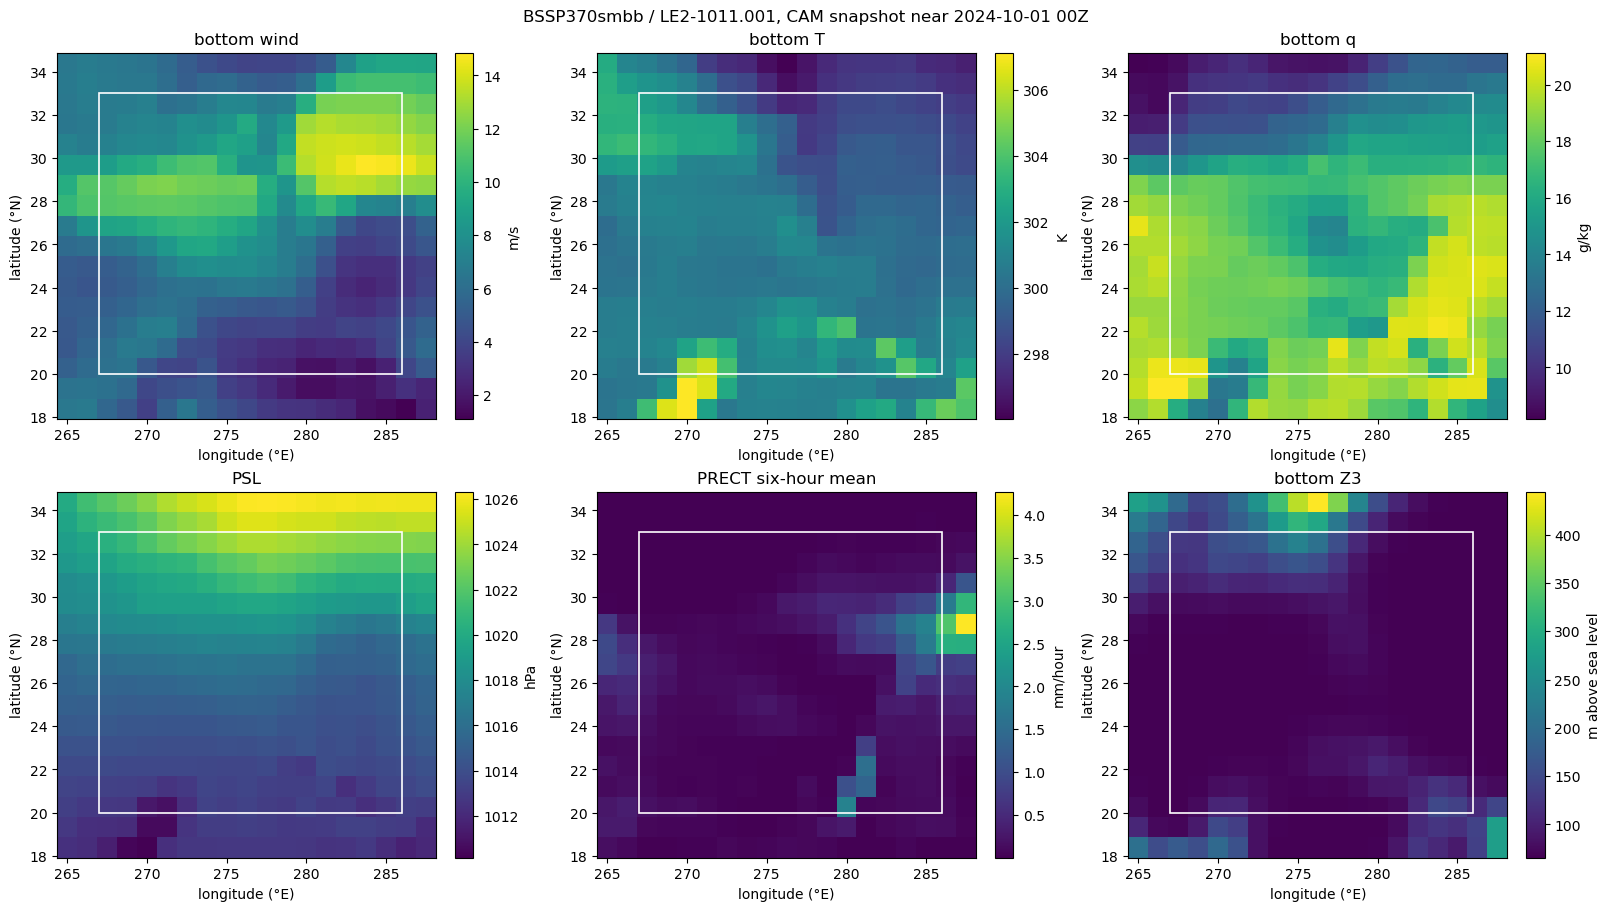

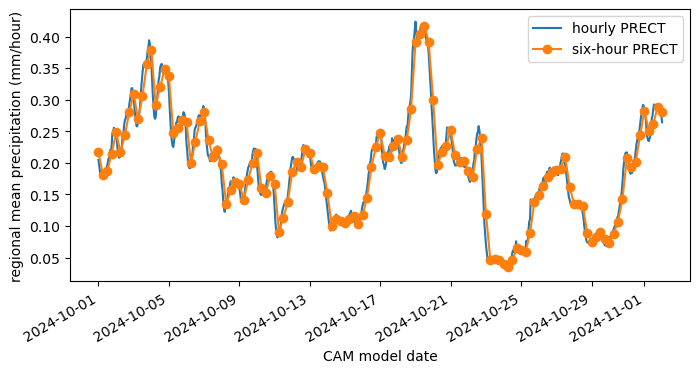

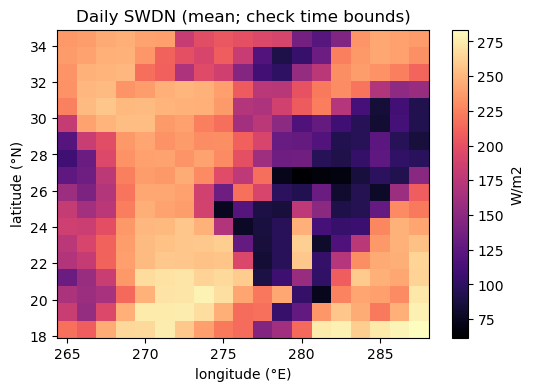

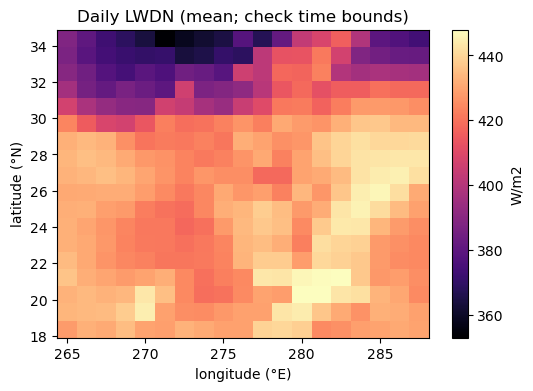

In [16]:
def nearest_record(a, when):
    t = a.time.values[0]
    key = type(t)(when.year, when.month, when.day, when.hour)
    return a.sel(time=key, method='nearest')

def show(fig, label):
    if SAVE_PLOTS:
        p = OUT / f'{CASE_NAME}_{label}.png'
        fig.savefig(p, dpi=160, bbox_inches='tight')
        print('Saved', p)
    plt.show()

lon, lat = ref.lon.values, ref.lat.values
snap = {k: nearest_record(v, SNAPSHOT).values for k, v in cam.items()}
wind = np.hypot(snap['U'], snap['V'])
panels = [('bottom wind', wind, 'm/s'),
          ('bottom T', snap['TBOT'], 'K'),
          ('bottom q', snap['SHUM']*1000, 'g/kg'),
          ('PSL', snap['PSLV']/100, 'hPa'),
          ('PRECT six-hour mean', snap['PREC']*3_600_000, 'mm/hour'),
          ('bottom Z3', snap['Z3'], 'm above sea level')]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)
for ax, (title, values, unit) in zip(axes.flat, panels):
    im = ax.pcolormesh(lon, lat, values, shading='auto', cmap='viridis')
    ax.add_patch(Rectangle((WEST, SOUTH), EAST-WEST, NORTH-SOUTH,
                           fill=False, edgecolor='white', linewidth=1.2))
    ax.set(title=title, xlabel='longitude (°E)', ylabel='latitude (°N)')
    fig.colorbar(im, ax=ax, label=unit)
fig.suptitle(f'{SCENARIO} / {MEMBER}, CAM snapshot near {SNAPSHOT:%Y-%m-%d %HZ}')
show(fig, 'CAM_fields')

if hourly is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot([as_datetime(t) for t in hourly.time.values],
            hourly.mean(('lat', 'lon')).values*3_600_000, label='hourly PRECT')
    ax.plot(dates, cam['PREC'].mean(('lat', 'lon')).values*3_600_000,
            marker='o', label='six-hour PRECT')
    ax.set(ylabel='regional mean precipitation (mm/hour)', xlabel='CAM model date')
    ax.legend()
    fig.autofmt_xdate()
    show(fig, 'PREC_cadence')

for slot, a in daily.items():
    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.pcolormesh(a.lon, a.lat, nearest_record(a, SNAPSHOT),
                       shading='auto', cmap='magma')
    ax.set(title=f'Daily {slot} (mean; check time bounds)', xlabel='longitude (°E)',
           ylabel='latitude (°N)')
    fig.colorbar(im, ax=ax, label=a.attrs.get('units', 'W/m²'))
    show(fig, slot+'_daily')

## 4. CAM source mesh and regional interpolation check

Cell edges are midpoints of adjacent CAM coordinates. The mesh has one quad per CAM cell, 1-based connectivity, and flattened `(lat, lon)` ordering matching the NetCDF fields. CDEPS uses this mesh for online bilinear remapping. The optional `RegularGridInterpolator` plot below samples a snapshot at regional ocean mesh centers; it checks coverage and resolution visually, and is **not written to the forcing file**.

Wrote source mesh: /glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/CESM2LE_CAM6_ESMFmesh.nc cells: 342


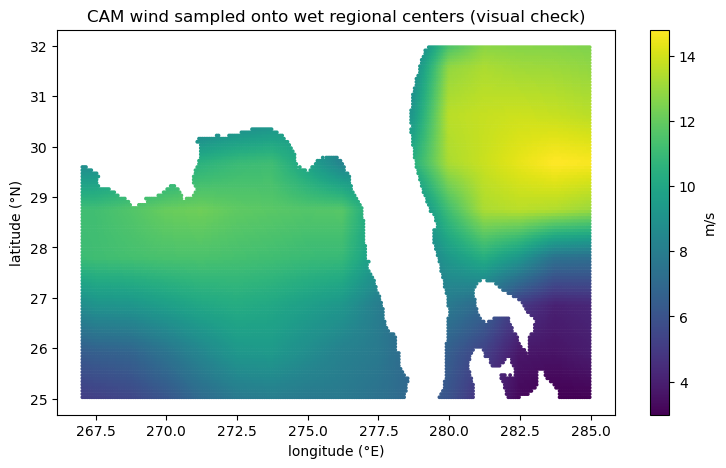

In [30]:
def edges(centers):
    mid = (centers[1:] + centers[:-1]) / 2
    return np.r_[centers[0]-(mid[0]-centers[0]), mid,
                 centers[-1]+(centers[-1]-mid[-1])]

lon_edges, lat_edges = edges(lon), edges(lat)
ny, nx = len(lat), len(lon)
node_lon, node_lat = np.meshgrid(lon_edges, lat_edges)
nodes = np.arange(1, (ny+1)*(nx+1)+1, dtype='int32').reshape(ny+1, nx+1)
conn = np.stack((nodes[:-1, :-1], nodes[:-1, 1:],
                 nodes[1:, 1:], nodes[1:, :-1]), axis=-1).reshape(ny*nx, 4)
center_lon, center_lat = np.meshgrid(lon, lat)
mesh = xr.Dataset(
    data_vars={
        'nodeCoords': (('nodeCount','coordDim'),
                       np.column_stack((node_lon.ravel(), node_lat.ravel())),
                       {'units':'degrees'}),
        'elementConn': (('elementCount','maxNodePElement'), conn, {'start_index':1}),
        'numElementConn': (('elementCount',), np.full(ny*nx, 4, dtype='int32')),
        'centerCoords': (('elementCount','coordDim'),
                         np.column_stack((center_lon.ravel(),center_lat.ravel())),
                         {'units':'degrees'}),
        'elementMask': (('elementCount',), np.ones(ny*nx, dtype='int32')),
        'origGridDims': (('origGridRank',), np.array([nx,ny],dtype='int32')),
    }, attrs={'gridType':'unstructured','version':'0.9',
              'conventions':'ESMFMESH','title':'Cropped regular CAM grid'})
mesh.to_netcdf(SOURCE_MESH, format='NETCDF4_CLASSIC',
               encoding={k:{'_FillValue':None} for k in mesh.variables})
with xr.open_dataset(SOURCE_MESH) as checkmesh:
    np.testing.assert_allclose(checkmesh.centerCoords.values,
                               np.column_stack((center_lon.ravel(),center_lat.ravel())))
    assert checkmesh.sizes['elementCount'] == ny*nx
print('Wrote source mesh:', SOURCE_MESH, 'cells:', ny*nx)

# For a regional check, use the target mesh if a CrocoDash case already exists.
if CASE.is_dir() and (CASE / 'env_run.xml').exists():
    entries = {e.get('id'):e.get('value') for e in ET.parse(CASE/'env_run.xml').iter('entry')}
    ocean_path = Path(entries['OCN_DOMAIN_MESH'])
    with xr.open_dataset(ocean_path) as om:
        coords = om.centerCoords.values.copy()
        mask = om.elementMask.values == 1
    coords[:,0] %= 360
    interp = RegularGridInterpolator((lat,lon), wind, bounds_error=False,
                                     fill_value=np.nan)
    regional = interp(np.column_stack((coords[mask,1],coords[mask,0])))
    assert np.isfinite(regional).all(), 'Ocean cells outside CAM crop; increase halo'
    fig, ax = plt.subplots(figsize=(9,5))
    im = ax.scatter(coords[mask,0],coords[mask,1],c=regional,s=3,cmap='viridis')
    ax.set(xlabel='longitude (°E)',ylabel='latitude (°N)',
           title='CAM wind sampled onto wet regional centers (visual check)')
    fig.colorbar(im,ax=ax,label='m/s')
    show(fig,'CAM_regional_preview')
else:
    print('Regional preview will be available after CrocoDash creates the new case.')

## 5. Write a six-hour CAM candidate file

The file preserves the source centers. CAM `PRECT` is multiplied by 1000 to convert m/s water equivalent to kg m⁻² s⁻¹. `PSL` supplies the sea-level pressure slot; `PS` and `Z3` remain diagnostics. Dates are encoded as Gregorian for this October interval; the strict six-hour check above prevents an unnoticed noleap/Gregorian leap-day gap.

In [18]:
time_coord = np.array(dates, dtype='datetime64[ns]')
names = {slot: OUTPUT_NAMES[slot] for slot in SIX_HOURLY}
contents = {}
for slot,a in cam.items():
    values = a.values.astype('float32')
    unit = a.attrs.get('units','')
    if slot == 'PREC':
        values *= 1000.     # m/s -> kg m-2 s-1 for water
        unit = 'kg m-2 s-1'
    attrs = {'units':unit,'source_variable':SIX_HOURLY[slot][0],
             'source_cell_methods':a.attrs.get('cell_methods','not specified')}
    if slot in ('U','V','TBOT','SHUM','Z3'):
        attrs['vertical_position'] = 'lowest CAM model level; not a standard reference height'
    contents[names[slot]] = (('time','lat','lon'), values, attrs)
forcing_candidates = xr.Dataset(contents,
    coords={'time':time_coord,'lat':lat.astype('float64'),
            'lon':lon.astype('float64')},
    attrs={'scenario':SCENARIO,'member':MEMBER,'source_calendar':'noleap',
           'purpose':'six-hourly CAM forcing candidates; no radiation proxy included'})
encoding = {name:{'zlib':True,'complevel':2,'_FillValue':np.float32(1e20)}
            for name in contents}
encoding['time'] = {'units':f'hours since {FORCING_START:%Y-%m-%d %H:%M:%S}',
                    'calendar':'gregorian'}
forcing_candidates.to_netcdf(CORE_FILE,format='NETCDF4_CLASSIC',encoding=encoding)
print('Wrote candidate file:', CORE_FILE)
print('CAM vertical source: inspect CAM_Z3_BOTTOM and reference heights before physics.')

Wrote candidate file: /glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/CESM2LE_CAM6_2024100100_2024110200_candidates.nc
CAM vertical source: inspect CAM_Z3_BOTTOM and reference heights before physics.


## 6. Optional eight-stream DATM plumbing input

For a technical run only, `PLUMBING_TEST=True` inserts daily `FSDS/FLDS` means into each six-hour record for that model date. This erases the diurnal radiation cycle, and daily time bounds may associate a daily mean with a different date. Inspect both source files' `time_bnds` and `cell_methods` before trusting even the daily flux integral. The bottom model level is well above conventional 10 m in the Florida subset. No lapse-rate correction is applied.

In [19]:
if PLUMBING_TEST:
    assert set(daily) == {'SWDN','LWDN'}, (
        'Find same-member daily FSDS and FLDS before an eight-stream test',daily.keys())
    extras = {}
    for slot, a in daily.items():
        assert a.attrs.get('units') in ('W/m2','W m-2','W/m^2')
        # This is an explicitly labeled proxy. Inspect source bounds separately.
        by_date = {as_datetime(t).date(): a.isel(time=i).values.astype('float32')
                   for i,t in enumerate(a.time.values)}
        missing = sorted({t.date() for t in dates} - set(by_date))
        assert not missing, ('Daily radiation lacks these dates',missing)
        values = np.stack([by_date[t.date()] for t in dates])
        assert np.isfinite(values).all()
        name = OUTPUT_NAMES[slot]
        extras[name] = (('time','lat','lon'),values,
                        {'units':'W m-2','source_variable':RADIATION[slot][0],
                         'daily_proxy':'same-date daily mean repeated each six-hour record'})
    full = forcing_candidates.assign(extras)
    full.attrs.update(purpose='CDEPS plumbing test: bottom level and daily radiation proxies')
    write_encoding = dict(encoding)
    write_encoding.update({k:{'zlib':True,'complevel':2,
                              '_FillValue':np.float32(1e20)} for k in extras})
    full.to_netcdf(FORCING_FILE,format='NETCDF4_CLASSIC',encoding=write_encoding)
    print('Wrote eight-field plumbing input:',FORCING_FILE)
else:
    print('Six-hour candidate file and source mesh are ready. Set PLUMBING_TEST=True '
          'after reviewing the limitations to prepare an eight-stream DATM case.')

Wrote eight-field plumbing input: /glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/CESM2LE_CAM6_2024100100_2024110200_DATM.nc


## 7. Inspect radiation time bounds

The archive `time` may label interval ends. Look at the bounds in both daily files and the precipitation file. This cell prints a small slice of source metadata; it does not change or shift data.

In [20]:
def show_time_metadata(path, source):
    with xr.open_dataset(path) as ds:
        da = ds[source]
        print(path.name, 'cell_methods=',da.attrs.get('cell_methods'),
              'bounds=',ds.time.attrs.get('bounds'))
        for key in (ds.time.attrs.get('bounds'),'time_bnds','time_bounds'):
            if key and key in ds:
                print(' ',key,'first:',ds[key].isel(time=0).values)
                break
for slot,paths in rad_paths.items():
    if paths: show_time_metadata(paths[0],RADIATION[slot][0])
show_time_metadata(six_paths['PREC'][0],SIX_HOURLY['PREC'][0])

b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h1.FSDS.20150101-20241231.nc cell_methods= time: mean bounds= time_bnds
  time_bnds first: [cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)]
b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h1.FLDS.20150101-20241231.nc cell_methods= time: mean bounds= time_bnds
  time_bnds first: [cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)]
b.e21.BSSP370smbb.f09_g17.LE2-1011.001.cam.h2.PRECT.2015010100-2024123100.nc cell_methods= time: mean bounds= time_bnds
  time_bnds first: [cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)
 cftime.DatetimeNoLeap(2015, 1, 1, 0, 0, 0, 0, has_year_zero=True)]


## 8. Validate the source mesh and candidate file

The source mesh `centerCoords` must exactly match the flattened NetCDF `(lat,lon)` cells. The plumbing file is checked only when that option is enabled.

In [21]:
check_file = FORCING_FILE if PLUMBING_TEST else CORE_FILE
with xr.open_dataset(check_file) as check, xr.open_dataset(SOURCE_MESH) as source:
    assert set(names.values()) <= set(check.data_vars)
    if PLUMBING_TEST:
        assert {OUTPUT_NAMES['SWDN'],OUTPUT_NAMES['LWDN']} <= set(check.data_vars)
    for key in check.data_vars:
        assert check[key].dims == ('time','lat','lon'), (key,check[key].dims)
        assert np.isfinite(check[key].values).all(),key
    np.testing.assert_allclose(source.centerCoords.values[:,0],
                               np.broadcast_to(check.lon.values,(ny,nx)).ravel())
    np.testing.assert_allclose(source.centerCoords.values[:,1],
                               np.broadcast_to(check.lat.values[:,None],(ny,nx)).ravel())
    assert np.all(source.elementMask.values == 1)
    np.testing.assert_array_equal(source.origGridDims.values,[nx,ny])
    print(check_file,dict(check.sizes),'mesh elements',source.sizes['elementCount'])

/glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/CESM2LE_CAM6_2024100100_2024110200_DATM.nc {'time': 129, 'lat': 18, 'lon': 19} mesh elements 342


## 9. Register a new, CAM-named DATM mode (plumbing test)

This reuses CDEPS `CORE_IAF_JRA` **field-processing code**, including its fixed reference-height behavior, while registering independent `CESM2LE_CAM6.*` stream names and CAM files. No JRA datafile, source grid, or stream slot is used. The following registration and case cells run only if `PLUMBING_TEST=True`. They edit three XML files in the selected CESM checkout; inspect the diff before creating a fresh case.

In [22]:
TARGETS = {
    'PREC':'Faxa_prec','LWDN':'Faxa_lwdn','SWDN':'Faxa_swdn',
    'SHUM':'Sa_shum','PSLV':'Sa_pslv','TBOT':'Sa_tbot',
    'U':'Sa_u','V':'Sa_v',
}
FIELDS = {slot: dict(source=OUTPUT_NAMES[slot],target=target,
                     tintalgo='nearest' if slot in ('PREC','LWDN','SWDN')
                     else 'linear',offset=0)
          for slot,target in TARGETS.items()}
assert set(FIELDS) == {'PREC','LWDN','SWDN','SHUM','PSLV','TBOT','U','V'}
assert len({s['target'] for s in FIELDS.values()}) == 8
assert len({s['source'] for s in FIELDS.values()}) == 8
mode_names = [f'{MODE_NAME}.{slot}' for slot in FIELDS]
print('CAM stream mappings:')
for slot, spec in FIELDS.items():
    print(f'  {MODE_NAME}.{slot}: {spec["source"]} -> {spec["target"]}')

CAM stream mappings:
  CESM2LE_CAM6.PREC: CAM_PRECT -> Faxa_prec
  CESM2LE_CAM6.LWDN: CAM_LWDN -> Faxa_lwdn
  CESM2LE_CAM6.SWDN: CAM_SWDN -> Faxa_swdn
  CESM2LE_CAM6.SHUM: CAM_Q_BOTTOM -> Sa_shum
  CESM2LE_CAM6.PSLV: CAM_PSL -> Sa_pslv
  CESM2LE_CAM6.TBOT: CAM_T_BOTTOM -> Sa_tbot
  CESM2LE_CAM6.U: CAM_UBOT -> Sa_u
  CESM2LE_CAM6.V: CAM_VBOT -> Sa_v


In [23]:
if PLUMBING_TEST:
    component_xml = CONFIG_DIR / 'config_component.xml'
    namelist_xml = CONFIG_DIR / 'namelist_definition_datm.xml'
    streams_xml = CONFIG_DIR / 'stream_definition_datm.xml'
    for path in (component_xml, namelist_xml, streams_xml):
        assert path.is_file(), ('Wrong CESM_ROOT?', path)

    mode_names = [f'{MODE_NAME}.{slot}' for slot in FIELDS]
    component_text = component_xml.read_text()
    namelist_text = namelist_xml.read_text()
    streams_text = streams_xml.read_text()

    def entry_block(document, entry_id):
        match = re.search(r'<entry id="' + re.escape(entry_id) +
                          r'"[^>]*>.*?</entry>', document, re.S)
        if match is None:
            raise ValueError(f'Could not find XML entry {entry_id}')
        return match

    # 1: Permit DATM_MODE=<MODE_NAME> in cases created from this checkout.
    match = entry_block(component_text, 'DATM_MODE')
    block = match.group()
    valid = re.search(r'<valid_values>([^<]*)</valid_values>', block)
    assert valid, 'DATM_MODE valid_values changed; inspect config_component.xml'
    allowed = [v.strip() for v in valid.group(1).split(',')]
    already_registered = MODE_NAME in allowed
    if not already_registered:
        updated = block[:valid.start(1)] + valid.group(1) + ',' + MODE_NAME + block[valid.end(1):]
        component_text = component_text[:match.start()] + updated + component_text[match.end():]

    # 2: Assign new stream names, but reuse the field-processing data mode.
    match = entry_block(namelist_text, 'streamslist')
    block = match.group()
    if f'datm_mode="{MODE_NAME}"' not in block:
        new_value = f'\n      <value datm_mode="{MODE_NAME}">\n        {",".join(mode_names)}\n      </value>'
        block = block.replace('<values>', '<values>' + new_value, 1)
        namelist_text = namelist_text[:match.start()] + block + namelist_text[match.end():]
    else:
        assert all(name in block for name in mode_names), 'Existing stream list conflicts with settings'

    match = entry_block(namelist_text, 'datamode')
    block = match.group()
    if f'datm_mode="{MODE_NAME}"' not in block:
        new_value = f'\n      <value datm_mode="{MODE_NAME}">CORE_IAF_JRA</value>'
        block = block.replace('<values>', '<values>' + new_value, 1)
        namelist_text = namelist_text[:match.start()] + block + namelist_text[match.end():]
    else:
        assert re.search(r'<value datm_mode="' + re.escape(MODE_NAME) +
                         r'">\s*CORE_IAF_JRA\s*</value>', block), 'Existing datamode differs'

    # 3: One independent source stream per field. All may read the same NetCDF.
    start_marker = f'  <!-- BEGIN notebook DATM mode {MODE_NAME} -->'
    end_marker = f'  <!-- END notebook DATM mode {MODE_NAME} -->'
    if already_registered and start_marker not in streams_text:
        raise ValueError(f'{MODE_NAME} already exists without this notebook block; choose a new MODE_NAME')
    parts = [start_marker]
    for slot, spec in FIELDS.items():
        file_name = str(FORCING_FILE.expanduser().resolve())
        mesh_name = str(SOURCE_MESH.expanduser().resolve())
        assert Path(file_name).is_file() and Path(mesh_name).is_file(), (slot, file_name, mesh_name)
        assert '\n' not in file_name + mesh_name + spec['source']
        parts.append(f'''  <stream_entry name="{escape(MODE_NAME)}.{escape(slot)}">
        <stream_meshfile><meshfile>{escape(mesh_name)}</meshfile></stream_meshfile>
        <stream_datafiles><file>{escape(file_name)}</file></stream_datafiles>
        <stream_datavars><var>{escape(spec['source'])} {escape(spec['target'])}</var></stream_datavars>
        <stream_lev_dimname>null</stream_lev_dimname>
        <stream_mapalgo><mapalgo>bilinear</mapalgo></stream_mapalgo>
        <stream_vectors>null</stream_vectors>
        <stream_year_align>{FORCING_START.year}</stream_year_align>
        <stream_year_first>{FORCING_START.year}</stream_year_first>
        <stream_year_last>{FORCING_END.year}</stream_year_last>
        <stream_offset>{int(spec['offset'])}</stream_offset>
        <stream_tintalgo><tintalgo>{spec['tintalgo']}</tintalgo></stream_tintalgo>
        <stream_taxmode><taxmode>limit</taxmode></stream_taxmode>
        <stream_dtlimit><dtlimit>1.5</dtlimit></stream_dtlimit>
        <stream_readmode>single</stream_readmode>
      </stream_entry>''')
    parts.append(end_marker)
    new_block = '\n'.join(parts)
    if start_marker in streams_text:
        assert streams_text.count(start_marker) == streams_text.count(end_marker) == 1
        left = streams_text.index(start_marker)
        right = streams_text.index(end_marker) + len(end_marker)
        streams_text = streams_text[:left] + new_block + streams_text[right:]
    else:
        assert streams_text.count('</stream_data>') == 1
        streams_text = streams_text.replace('</stream_data>', new_block + '\n\n</stream_data>')

    # Parse all files before writing any of them.
    for path, value in ((component_xml, component_text),
                        (namelist_xml, namelist_text), (streams_xml, streams_text)):
        ET.fromstring(value)
        if path.read_text() != value:
            path.write_text(value)
            print('Updated:', path)
        else:
            print('Already current:', path)
    print('Registered', MODE_NAME, 'with', len(FIELDS), 'dataset named streams.')

Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/config_component.xml
Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/namelist_definition_datm.xml
Updated: /glade/work/hmnguyen/crocodile2026/CESM/components/cdeps/datm/cime_config/stream_definition_datm.xml
Registered CESM2LE_CAM6 with 8 dataset named streams.


**Terminal (CLI): inspect the CDEPS edits**

```bash
cd <CESM_checkout>/components/cdeps
git diff -- datm/cime_config/config_component.xml datm/cime_config/namelist_definition_datm.xml datm/cime_config/stream_definition_datm.xml
```

The checkout is shared by its cases. Choose a new `MODE_NAME` if a different forcing period or member must coexist.

## CHECKPOINT A — create a fresh CrocoDash case

Only after `PLUMBING_TEST=True`, create the new `CASE_NAME` with the **same CESM checkout** whose CDEPS XML was edited. Use `MODEL_*` settings above. Keep the known working ocean-only `CR_JRA` compset as its starting component selection; setting `DATM_MODE` later selects the CAM stream definitions. A new compset alias is optional, not a rename. Run your usual CrocoDash case-creation calls, then GLORYS IC/OBC:

```python
from CrocoDash.grid import Grid
grid = Grid(resolution=MODEL_RESOLUTION,
            xstart=MODEL_WEST, lenx=MODEL_EAST-MODEL_WEST,
            ystart=MODEL_SOUTH, leny=MODEL_NORTH-MODEL_SOUTH,
            name=INPUT_NAME)
# Pass grid and CASE_NAME to your established CrocoDash case-creation workflow.
case.configure_forcings(date_range=GLORYS_DATE_RANGE,
    boundaries=['south','north','west','east'], product_name='GLORYS',
    function_name='get_glorys_data_from_rda')
case.process_forcings()
```

Return here once the new case has `env_run.xml`. Variables from this notebook are not shared with a separate kernel.

In [27]:
if PLUMBING_TEST:
    assert CASE.is_dir(), f'Create the new CrocoDash case first: {CASE}'
    assert (CASE / 'env_run.xml').is_file()
    entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
    print({key: entries.get(key) for key in
           ('DATM_MODE', 'CALENDAR', 'RUN_STARTDATE', 'OCN_DOMAIN_MESH', 'ATM_DOMAIN_MESH')})
    assert entries.get('CALENDAR', '').lower() in ('gregorian', 'standard')
    ocean_mesh = Path(entries['OCN_DOMAIN_MESH'])
    assert ocean_mesh.is_file(), ocean_mesh
    assert INPUT_NAME in str(ocean_mesh), ('Check INPUT_NAME and ocean mesh', ocean_mesh)

    datm_entry = next(e for e in ET.parse(CASE / 'env_run.xml').iter('entry')
                      if e.get('id') == 'DATM_MODE')
    case_allowed = datm_entry.find('valid_values')
    if case_allowed is not None:
        assert MODE_NAME in (case_allowed.text or '').split(','), (
            'Case does not recognize the new mode. Create it after the CDEPS XML edits.', MODE_NAME)

{'DATM_MODE': 'CORE_IAF_JRA_1p5_2023', 'CALENDAR': 'GREGORIAN', 'RUN_STARTDATE': '2024-10-01', 'OCN_DOMAIN_MESH': '/glade/work/hmnguyen/crocodile2026/croc_input/florida_storm_cam6_test/ocn/ESMF_mesh_florida_storm_cam6_test_edc315.nc', 'ATM_DOMAIN_MESH': '/glade/campaign/cesm/cesmdata/inputdata/share/meshes/TL319_151007_ESMFmesh.nc'}


### All-active regional ATM model mesh

Copy the new case's ocean ESMF mesh, setting `elementMask=1` for every ATM cell. This is the **target** mesh. Keep the ocean wet/dry mask intact. The CAM source mesh is the separate file written above.

In [28]:
if PLUMBING_TEST:
    assert ocean_mesh.resolve() != ATM_MESH.resolve()
    shutil.copy2(ocean_mesh, ATM_MESH)
    with Dataset(ATM_MESH, 'r+') as nc:
        mask = nc.variables['elementMask']
        mask[:] = np.ones(mask.shape, dtype=mask.dtype)
    with Dataset(ATM_MESH) as atm, Dataset(ocean_mesh) as ocn:
        atm_mask = np.asarray(atm.variables['elementMask'][:])
        ocn_mask = np.asarray(ocn.variables['elementMask'][:])
        assert np.all(atm_mask == 1)
        assert np.any(ocn_mask == 1)
        print('Ocean mask:', dict(zip(*[v.tolist() for v in np.unique(ocn_mask, return_counts=True)])))
        print('ATM mesh:', ATM_MESH, 'elements:', len(atm_mask), 'all active')
        centers = np.asarray(ocn.variables['centerCoords'][:])
        wet = centers[ocn_mask == 1]
        wet[:, 0] %= 360
        outside = ((wet[:, 0] < lon_edges[0]) | (wet[:, 0] > lon_edges[-1]) |
                   (wet[:, 1] < lat_edges[0]) | (wet[:, 1] > lat_edges[-1]))
        assert outside.sum() == 0, f'{outside.sum()} wet ocean cells outside CAM source mesh'

Ocean mask: {0: 10392, 1: 21864}
ATM mesh: /glade/work/hmnguyen/cam6_forcing/florida_storm_cam6_test/Regional_ATM_ESMFmesh.nc elements: 32256 all active


### Remove stale CrocoDash JRA stream-year overrides

CrocoDash may write a JRA stream-year block as part of GLORYS setup. The CAM mode defines its own streams. Remove that generated block, and stop if another active manual override needs review.

In [29]:
if PLUMBING_TEST:
    override_file = CASE / 'user_nl_datm_streams'
    existing = override_file.read_text() if override_file.exists() else ''
    auto_block = re.compile(
        r'(?ms)^! >>> CrocoDash configure_forcings: StreamYears[^\n]*\n'
        r'.*?^! <<< CrocoDash configure_forcings: StreamYears[^\n]*(?:\n|$)'
    )
    cleaned, removed = auto_block.subn('', existing)
    assert removed <= 1 and 'CrocoDash configure_forcings: StreamYears' not in cleaned
    active_lines = [line for line in cleaned.splitlines()
                    if line.strip() and not line.lstrip().startswith('!')]
    assert not active_lines, ('Inspect unrelated DATM stream overrides before proceeding', active_lines)
    if cleaned != existing:
        override_file.write_text(cleaned)
    print('Removed stale JRA StreamYears block:', removed)

Removed stale JRA StreamYears block: 0


**Terminal (CLI): select CAM DATM and preview namelists**

Substitute values printed by **User settings**. `ATM_DOMAIN_MESH` is the all-active **regional target**; the CAM source mesh stays in the new stream definitions. Do not change `OCN_DOMAIN_MESH`.

```bash
cd <new_case_directory>
./xmlchange DATM_MODE=<MODE_NAME>,ATM_DOMAIN_MESH=<regional_ATM_mesh_path>
./xmlchange RUN_STARTDATE=<YYYY-MM-DD>,STOP_OPTION=<ndays_or_nhours>,STOP_N=<integer>,HIST_OPTION=<history_option>,HIST_N=<integer>
./preview_namelists
./xmlquery COMPSET DATM_MODE
```

If `DATM_MODE` is invalid, the case was generated before the mode registration or from a different CESM checkout. Create a fresh case using the edited checkout.

## 10. Validate the generated DATM configuration

Check the mode, regional target mesh, and all eight CAM-named streams. `datamode=CORE_IAF_JRA` is the reused field-processing routine, while `DATM_MODE` selects CAM streams. No active stream may still read a JRA forcing file.

In [31]:
if PLUMBING_TEST:
    run_entries = {e.get('id'): e.get('value') for e in ET.parse(CASE / 'env_run.xml').iter('entry')}
    assert run_entries.get('DATM_MODE') == MODE_NAME, run_entries.get('DATM_MODE')
    assert run_entries.get('ATM_DOMAIN_MESH') == str(ATM_MESH)
    assert run_entries.get('OCN_DOMAIN_MESH') == str(ocean_mesh)
    assert run_entries.get('RUN_STARTDATE') == f'{RUN_START:%Y-%m-%d}'
    assert run_entries.get('STOP_OPTION') == STOP_OPTION
    assert int(run_entries.get('STOP_N', '-1')) == STOP_N
    assert run_entries.get('HIST_OPTION') == HIST_OPTION
    assert int(run_entries.get('HIST_N', '-1')) == HIST_N

    datm_in = (CASE / 'CaseDocs/datm_in').read_text()
    assert re.search(r'''(?im)^\s*datamode\s*=\s*['"]CORE_IAF_JRA['"]''', datm_in)
    for name in ('model_meshfile', 'model_maskfile'):
        match = re.search(rf'''(?im)^\s*{name}\s*=\s*['"]([^'"]+)['"]''', datm_in)
        assert match, f'{name} missing in CaseDocs/datm_in'
        assert Path(match.group(1)) == ATM_MESH, (name, match.group(1))

    generated = ET.parse(CASE / 'CaseDocs/datm.streams.xml').getroot()
    seen = set()
    for stream in generated.iter('stream_info'):
        name = stream.get('name', '')
        assert not name.startswith('CORE_IAF_JRA'), name
        assert all('/jra55/' not in (node.text or '').lower()
                   for node in stream.findall('./datafiles/file')), name
        if name not in mode_names:
            continue                   # Other optional component streams may exist.
        slot = name.split('.', 1)[1]
        assert slot not in seen, name
        seen.add(slot)
        spec = FIELDS[slot]
        expected_file = str(FORCING_FILE.expanduser().resolve())
        expected_mesh = str(SOURCE_MESH.expanduser().resolve())
        files = [node.text for node in stream.findall('./datafiles/file')]
        pairs = [(node.text or '').split() for node in stream.findall('./datavars/var')]
        assert files == [expected_file], (name, files)
        assert stream.findtext('meshfile') == expected_mesh, name
        assert pairs == [[spec['source'], spec['target']]], (name, pairs)
        assert stream.findtext('taxmode') == 'limit'
        assert stream.findtext('tintalgo') == spec['tintalgo']
        assert stream.findtext('mapalgo') == 'bilinear'
        assert stream.findtext('offset') == str(int(spec['offset']))
        assert [stream.findtext(k) for k in ('year_first', 'year_last', 'year_align')] == [
            str(FORCING_START.year), str(FORCING_END.year), str(FORCING_START.year)]
        print(f'{name}: {spec["source"]} -> {spec["target"]}')
    assert seen == set(FIELDS), ('Missing dataset streams', set(FIELDS) - seen)
    print('Dataset named forcing streams and regional ATM mesh verified. Ready to build.')

CESM2LE_CAM6.PREC: CAM_PRECT -> Faxa_prec
CESM2LE_CAM6.LWDN: CAM_LWDN -> Faxa_lwdn
CESM2LE_CAM6.SWDN: CAM_SWDN -> Faxa_swdn
CESM2LE_CAM6.SHUM: CAM_Q_BOTTOM -> Sa_shum
CESM2LE_CAM6.PSLV: CAM_PSL -> Sa_pslv
CESM2LE_CAM6.TBOT: CAM_T_BOTTOM -> Sa_tbot
CESM2LE_CAM6.U: CAM_UBOT -> Sa_u
CESM2LE_CAM6.V: CAM_VBOT -> Sa_v
Dataset named forcing streams and regional ATM mesh verified. Ready to build.


**Terminal (CLI): build and run**

After the preceding validation succeeds:

```bash
cd <new_case_directory>
./case.build
./case.submit
```

Check the current `CaseStatus`, `atm.log`, and `med.log`; compare `atmImp_Sa_u`/`atmImp_Sa_v` in the coupler history with the CAM preview. The CAM member does not reproduce observed Milton. For scientific flux experiments, replace the daily radiation proxy with suitable subdaily inputs, resolve the bottom-level reference-height mismatch, inspect precipitation/radiation time bounds, and compare the resulting forcing against independent observations. MOM6 output frequency is controlled separately by its `diag_table`.